# Apoferritin Dataset Phase Retrieval

> Georgios Varnavides | Jan 12 2025  
>
> Sample: apoferritin PDB dataset  
> Sampling conditions: 10 A step-size  
> Imaging conditions: 300 kV, 4 mrad, 1.5 um defocus  
> Dose conditions: 100 e/A2  

A simulated apoferritin dataset under cryo-EM conditions: a small aperture, a large defocus and a
low dose. We reconstruct it with parallax, upsampled four times, and compare the six kernels.

In [ ]:
# %load_ext autoreload 
# %autoreload 2

In [1]:
import quantem as em
import numpy as np

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

We load the simulated dataset, keep the first 48 x 48 scan positions, and set the conditions it was
simulated with.

In [2]:
dataset = em.core.io.load("../../data/apoF_4mrad_1.5um-df_10A-step.zip")
dataset = em.core.datastructures.Dataset.from_array(
    dataset.array[:48,:48],
    sampling=dataset.sampling,
    units=dataset.units
)
dataset

Dataset(shape=(48, 48, 128, 128), dtype=float32, name='4d dataset')
  sampling: [10.66666667 10.66666667  0.15380851  0.15380851]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [3]:
energy = 300e3
semiangle_cutoff = 4
defocus = 1.5e4
rotation_angle_deg = -15

## Finite dose

Poisson counts at 100 electrons per square Angstrom, which is 1e4 electrons per pattern at a 10 A
step:

In [4]:
def add_poisson_noise(
    dataset,
    electrons_per_area,
):
    if electrons_per_area == np.inf:
        return dataset
    electrons_per_probe = electrons_per_area * dataset.sampling[:2].prod()
    
    dataset_noisy = dataset.copy()
    dataset_noisy.array = np.random.poisson(dataset.array * electrons_per_probe)
    return dataset_noisy

In [5]:
np.random.seed(2025)
noisy_dataset = add_poisson_noise(
    dataset,
    100
)

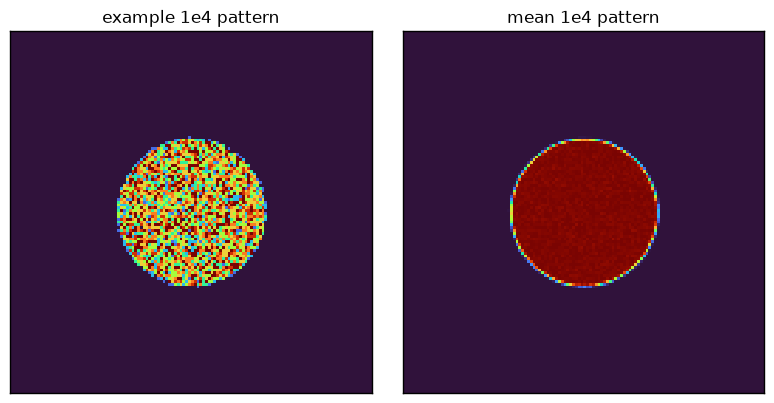

In [6]:
em.visualization.show_2d(
    [
        noisy_dataset[0,0].array,
        noisy_dataset.mean((0,1)),
    ],
    title=[
        "example 1e4 pattern","mean 1e4 pattern"
    ],
    power=0.5,
    cmap='turbo'
);

## Reconstruction

We start from the known defocus and rotation angle.

In [7]:
direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    noisy_dataset,
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=rotation_angle_deg,
    aberration_coefs={"defocus":defocus},
    # device='gpu',
)

The defocus shifts the bright-field images relative to one another, and parallax aligns them and
sums them. Upsampled four times:

Reconstructing with:

 HyperparameterState(
  current_aberrations={'C10': -15000.0},
  current_rotation_angle_deg=-15,
)


100%|██████████| 2217/2217 [00:00<00:00, 12892.01it/s]


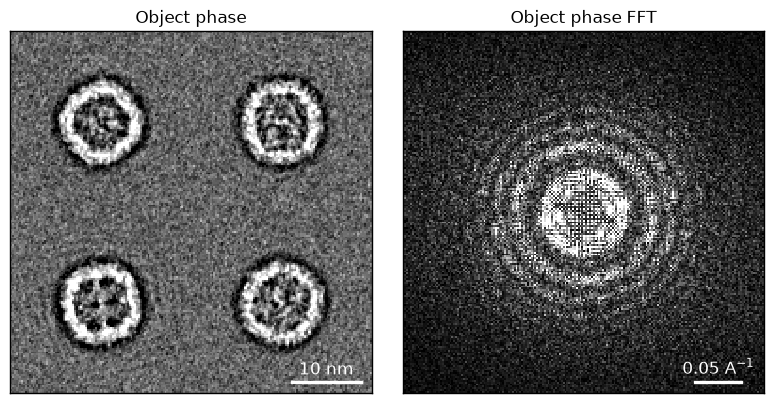

In [8]:
direct_ptycho.reconstruct(
    deconvolution_kernel='prlx',
    upsampling_factor=4
).visualize()

The particles' shells and some internal detail come through, and the Fourier transform carries the
contrast transfer rings past the scan's own Nyquist frequency, 0.05 A^-1.

The six kernels at the scan's own sampling:

100%|██████████| 6/6 [00:01<00:00,  3.44it/s]


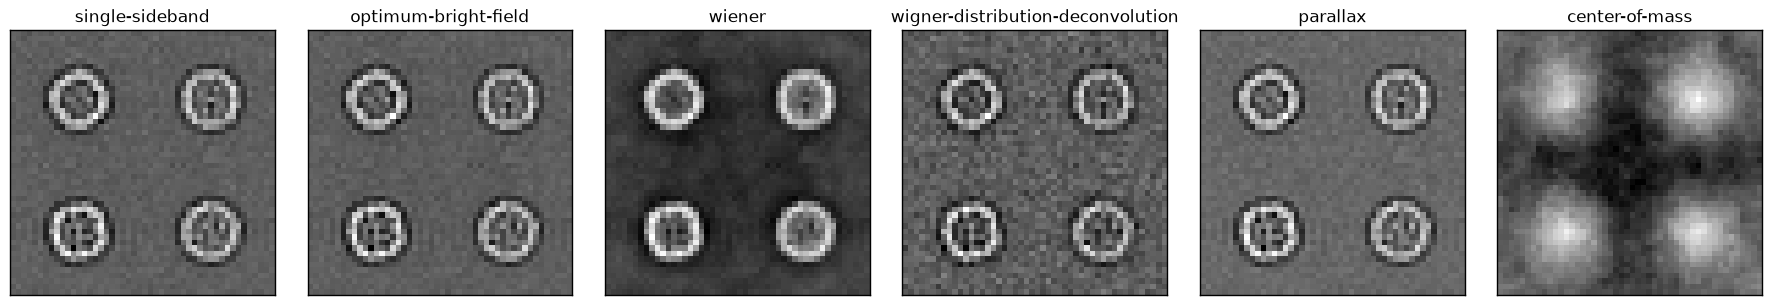

In [9]:
kwargs = {
    "title":["single-sideband","optimum-bright-field","wiener","wigner-distribution-deconvolution","parallax","center-of-mass"],
    "norm":"minmax",
    "axsize":(3,3),
}

recons = direct_ptycho._reconstruct_all_permutations()

em.visualization.show_2d(
    recons,
    **kwargs
);

All but the center of mass resolve the four particles, and Wiener also keeps their mean phase.

`max_batch_size` sets how many bright-field pixels are processed at once, which limits the memory a
reconstruction needs without changing the result:

Reconstructing with:

 HyperparameterState(
  current_aberrations={'C10': -15000.0},
  current_rotation_angle_deg=-15,
)


100%|██████████| 2217/2217 [00:00<00:00, 14649.04it/s]


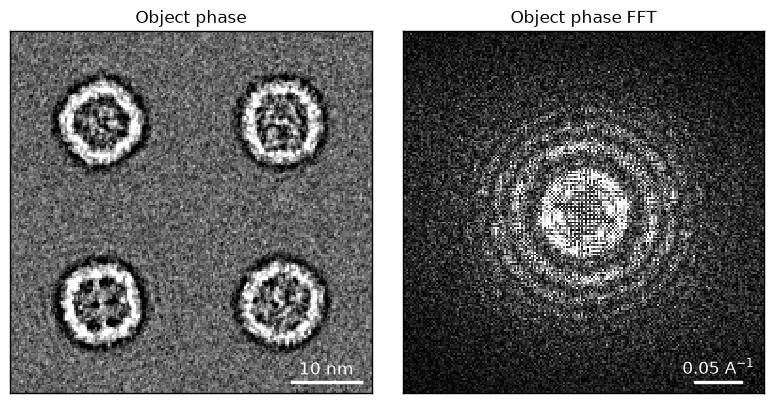

In [17]:
direct_ptycho.reconstruct(
    deconvolution_kernel='prlx',
    upsampling_factor=4,
    max_batch_size=501,
).visualize(
)